In [ ]:
import os

# Dataset
from sklearn.datasets import load_wine

# Data manipulation
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Data preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.decomposition import PCA

# Regression models
from sklearn.cluster import KMeans
# Evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

In [24]:

# Results directory (relative to project root)
RESULTS_DIR = "../../results/clustering"
os.makedirs(RESULTS_DIR, exist_ok=True)

RESULTS_FILE = os.path.join(RESULTS_DIR, "clustering_metrics.csv")


def save_clustering_results(model_name, X, cluster_labels,
                            y_true=None, dataset="test"):

    # Number of unique clusters
    unique_labels = np.unique(cluster_labels)

    # DBSCAN can assign -1 to noise points.
    # Exclude noise when calculating internal metrics.
    non_noise_mask = cluster_labels != -1

    X_eval = X[non_noise_mask]
    labels_eval = cluster_labels[non_noise_mask]

    n_clusters = len(np.unique(labels_eval))
    n_noise = np.sum(cluster_labels == -1)

    # Base results
    results = {
        "Model": model_name,
        "Dataset": dataset,
        "N_Clusters": n_clusters,
        "N_Noise": n_noise,
        "Silhouette_Score": np.nan,
        "Davies_Bouldin_Index": np.nan,
        "Calinski_Harabasz_Score": np.nan,
        "ARI": np.nan
    }

    # Internal metrics require at least 2 clusters
    # and fewer clusters than samples.
    if 1 < n_clusters < len(labels_eval):

        results["Silhouette_Score"] = silhouette_score(
            X_eval, labels_eval
        )

        results["Davies_Bouldin_Index"] = davies_bouldin_score(
            X_eval, labels_eval
        )

        results["Calinski_Harabasz_Score"] = calinski_harabasz_score(
            X_eval, labels_eval
        )

    # External metric: requires actual ground-truth labels
    if y_true is not None:
        results["ARI"] = adjusted_rand_score(
            y_true, cluster_labels
        )

    # Save results
    df = pd.DataFrame([results])

    df.to_csv(
        RESULTS_FILE,
        mode="a",
        header=not os.path.exists(RESULTS_FILE),
        index=False
    )

    print(f"{model_name} clustering metrics saved successfully!")


In [ ]:
wine = load_wine()

X = wine.data
y = wine.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Features:", wine.feature_names)
print("Actual classes:", wine.target_names)

Dataset shape: (178, 13)
Target shape: (178,)
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Actual classes: ['class_0' 'class_1' 'class_2']


In [ ]:
df = pd.DataFrame(
    X,
    columns=wine.feature_names
)

df["Actual_Species"] = [
    wine.target_names[i] for i in y
]

display(df.head())

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Actual_Species
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


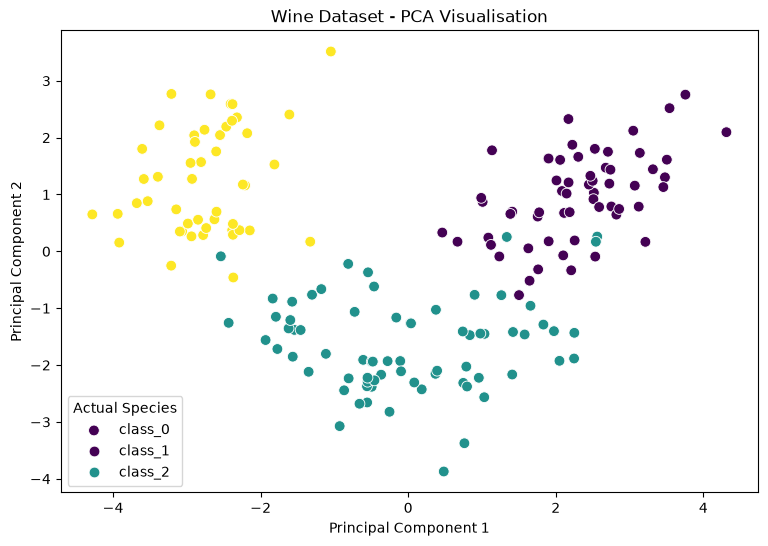

Variance explained: 0.5540633835693528


In [ ]:

pca = PCA(n_components=2)

X_pca = pca.fit_transform(
    StandardScaler().fit_transform(X)
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=y,
    palette="viridis",
    s=60
)

plt.title("Wine Dataset - PCA Visualisation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(
    labels=wine.target_names,
    title="Actual Species"
)

plt.show()

print(
    "Variance explained:",
    pca.explained_variance_ratio_.sum()
)


In [28]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original feature means:", X.mean(axis=0))
print("Scaled feature means:", X_scaled.mean(axis=0))

print("\nScaled feature standard deviations:", X_scaled.std(axis=0))


Original feature means: [1.30006180e+01 2.33634831e+00 2.36651685e+00 1.94949438e+01
 9.97415730e+01 2.29511236e+00 2.02926966e+00 3.61853933e-01
 1.59089888e+00 5.05808988e+00 9.57449438e-01 2.61168539e+00
 7.46893258e+02]
Scaled feature means: [ 7.84141790e-15  2.44498554e-16 -4.05917497e-15 -7.11041712e-17
 -2.49488320e-17 -1.95536471e-16  9.44313292e-16 -4.17892936e-16
 -1.54059038e-15 -4.12903170e-16  1.39838203e-15  2.12688793e-15
 -6.98567296e-17]

Scaled feature standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [29]:

k_values = range(2, 8)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(X_scaled, cluster_labels)
    )

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

display(results)


,K,Inertia,Silhouette_Score
0,2,1658.758852,0.259317
1,3,1277.928489,0.284859
2,4,1175.428333,0.260170
3,5,1109.512739,0.201619
4,6,1046.002333,0.237167
5,7,981.595233,0.203628


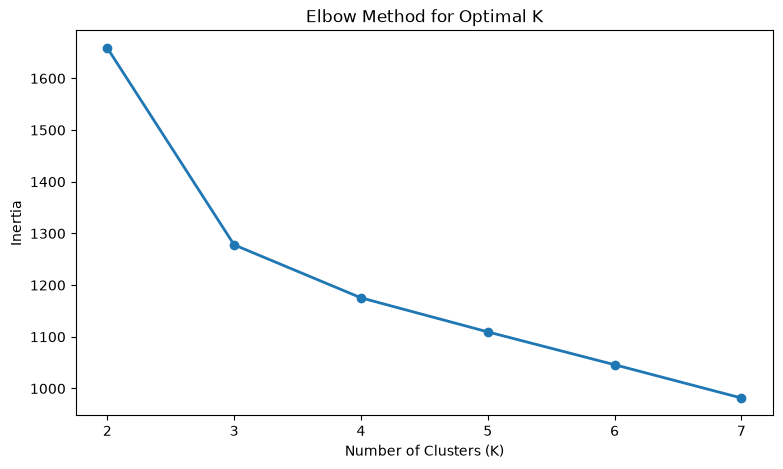

In [30]:

plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.show()


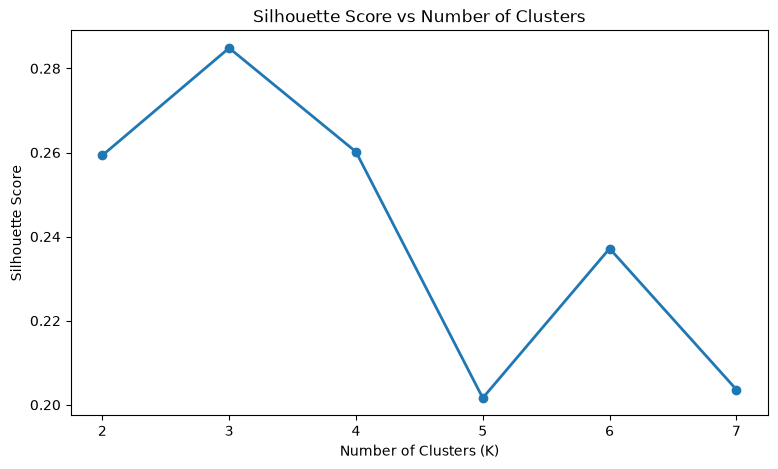

In [31]:

plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    silhouette_values,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs Number of Clusters")
plt.xticks(list(k_values))
plt.show()


In [32]:

# Model 1: Default K-Means
model1 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=3,
        random_state=42
    ))
])


# Model 2: K-Means++ Initialisation
model2 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=10,
        random_state=42
    ))
])


# Model 3: Random Initialisation
model3 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=3,
        init="random",
        n_init=10,
        random_state=42
    ))
])


# Model 4: Higher Number of Initialisations
model4 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=20,
        random_state=42
    ))
])


# Model 5: Different Number of Clusters (K=3)
model5 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=10,
        random_state=42
    ))
])


# Model 6: Different Number of Clusters (K=5)
model6 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=4,
        init="k-means++",
        n_init=10,
        random_state=42
    ))
])


# Model 7: Lower Maximum Iterations
model7 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=10,
        max_iter=100,
        random_state=42
    ))
])


# Model 8: Higher Maximum Iterations
model8 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=10,
        max_iter=500,
        random_state=42
    ))
])


# Model 9: Strict Convergence Tolerance
model9 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=10,
        tol=1e-6,
        max_iter=500,
        random_state=42
    ))
])


# Model 10: Weak Convergence Tolerance
model10 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=10,
        tol=1e-2,
        max_iter=500,
        random_state=42
    ))
])


In [33]:
models = {
    "KMeans_Default": model1,
    "KMeans_KPlusPlus": model2,
    "KMeans_Random_Init": model3,
    "KMeans_High_NInit": model4,
    "KMeans_K3": model5,
    "KMeans_K5": model6,
    "KMeans_Low_Iterations": model7,
    "KMeans_High_Iterations": model8,
    "KMeans_Strict_Tolerance": model9,
    "KMeans_Weak_Tolerance": model10
}

In [34]:
def train_models(models, X):
    for name, model in models.items():
        model.fit(X)
        print(f"{name} trained successfully!")


train_models(models, X)

KMeans_Default trained successfully!
KMeans_KPlusPlus trained successfully!
KMeans_Random_Init trained successfully!
KMeans_High_NInit trained successfully!
KMeans_K3 trained successfully!
KMeans_K5 trained successfully!
KMeans_Low_Iterations trained successfully!
KMeans_High_Iterations trained successfully!
KMeans_Strict_Tolerance trained successfully!
KMeans_Weak_Tolerance trained successfully!


In [35]:
for name, model in models.items():

    cluster_labels = model.predict(X)

    save_clustering_results(
        model_name=name,
        X=model.named_steps["scaler"].transform(X),
        cluster_labels=cluster_labels,
        y_true=y,
        dataset="make_blobs"
    )

KMeans_Default clustering metrics saved successfully!
KMeans_KPlusPlus clustering metrics saved successfully!
KMeans_Random_Init clustering metrics saved successfully!
KMeans_High_NInit clustering metrics saved successfully!
KMeans_K3 clustering metrics saved successfully!
KMeans_K5 clustering metrics saved successfully!
KMeans_Low_Iterations clustering metrics saved successfully!
KMeans_High_Iterations clustering metrics saved successfully!
KMeans_Strict_Tolerance clustering metrics saved successfully!
KMeans_Weak_Tolerance clustering metrics saved successfully!


In [36]:
comparison_results = []

for name, model in models.items():

    cluster_labels = model.predict(X)

    X_scaled = model.named_steps["scaler"].transform(X)

    unique_clusters = np.unique(cluster_labels)

    results = {
        "Model": name,
        "N_Clusters": len(unique_clusters),
        "Inertia": model.named_steps["model"].inertia_,
        "Iterations": model.named_steps["model"].n_iter_,
        "Silhouette": np.nan,
        "Davies_Bouldin": np.nan,
        "Calinski_Harabasz": np.nan,
        "ARI": adjusted_rand_score(y, cluster_labels)
    }

    if 1 < len(unique_clusters) < len(cluster_labels):

        results["Silhouette"] = silhouette_score(
            X_scaled, cluster_labels
        )

        results["Davies_Bouldin"] = davies_bouldin_score(
            X_scaled, cluster_labels
        )

        results["Calinski_Harabasz"] = calinski_harabasz_score(
            X_scaled, cluster_labels
        )

    comparison_results.append(results)


comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        by="Silhouette",
        ascending=False
    )
)

,Model,N_Clusters,Inertia,Iterations,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI
0,KMeans_Default,3,1277.928489,7,0.284859,1.389188,70.940008,0.897495
1,KMeans_KPlusPlus,3,1277.928489,7,0.284859,1.389188,70.940008,0.897495
2,KMeans_Random_Init,3,1277.928489,7,0.284859,1.389188,70.940008,0.897495
3,KMeans_High_NInit,3,1277.928489,7,0.284859,1.389188,70.940008,0.897495
4,KMeans_K3,3,1277.928489,7,0.284859,1.389188,70.940008,0.897495
6,KMeans_Low_Iterations,3,1277.928489,7,0.284859,1.389188,70.940008,0.897495
7,KMeans_High_Iterations,3,1277.928489,7,0.284859,1.389188,70.940008,0.897495
8,KMeans_Strict_Tolerance,3,1277.928489,7,0.284859,1.389188,70.940008,0.897495
9,KMeans_Weak_Tolerance,3,1277.928489,6,0.284859,1.389188,70.940008,0.897495
5,KMeans_K5,4,1175.428333,13,0.260170,1.796892,56.181355,0.764564


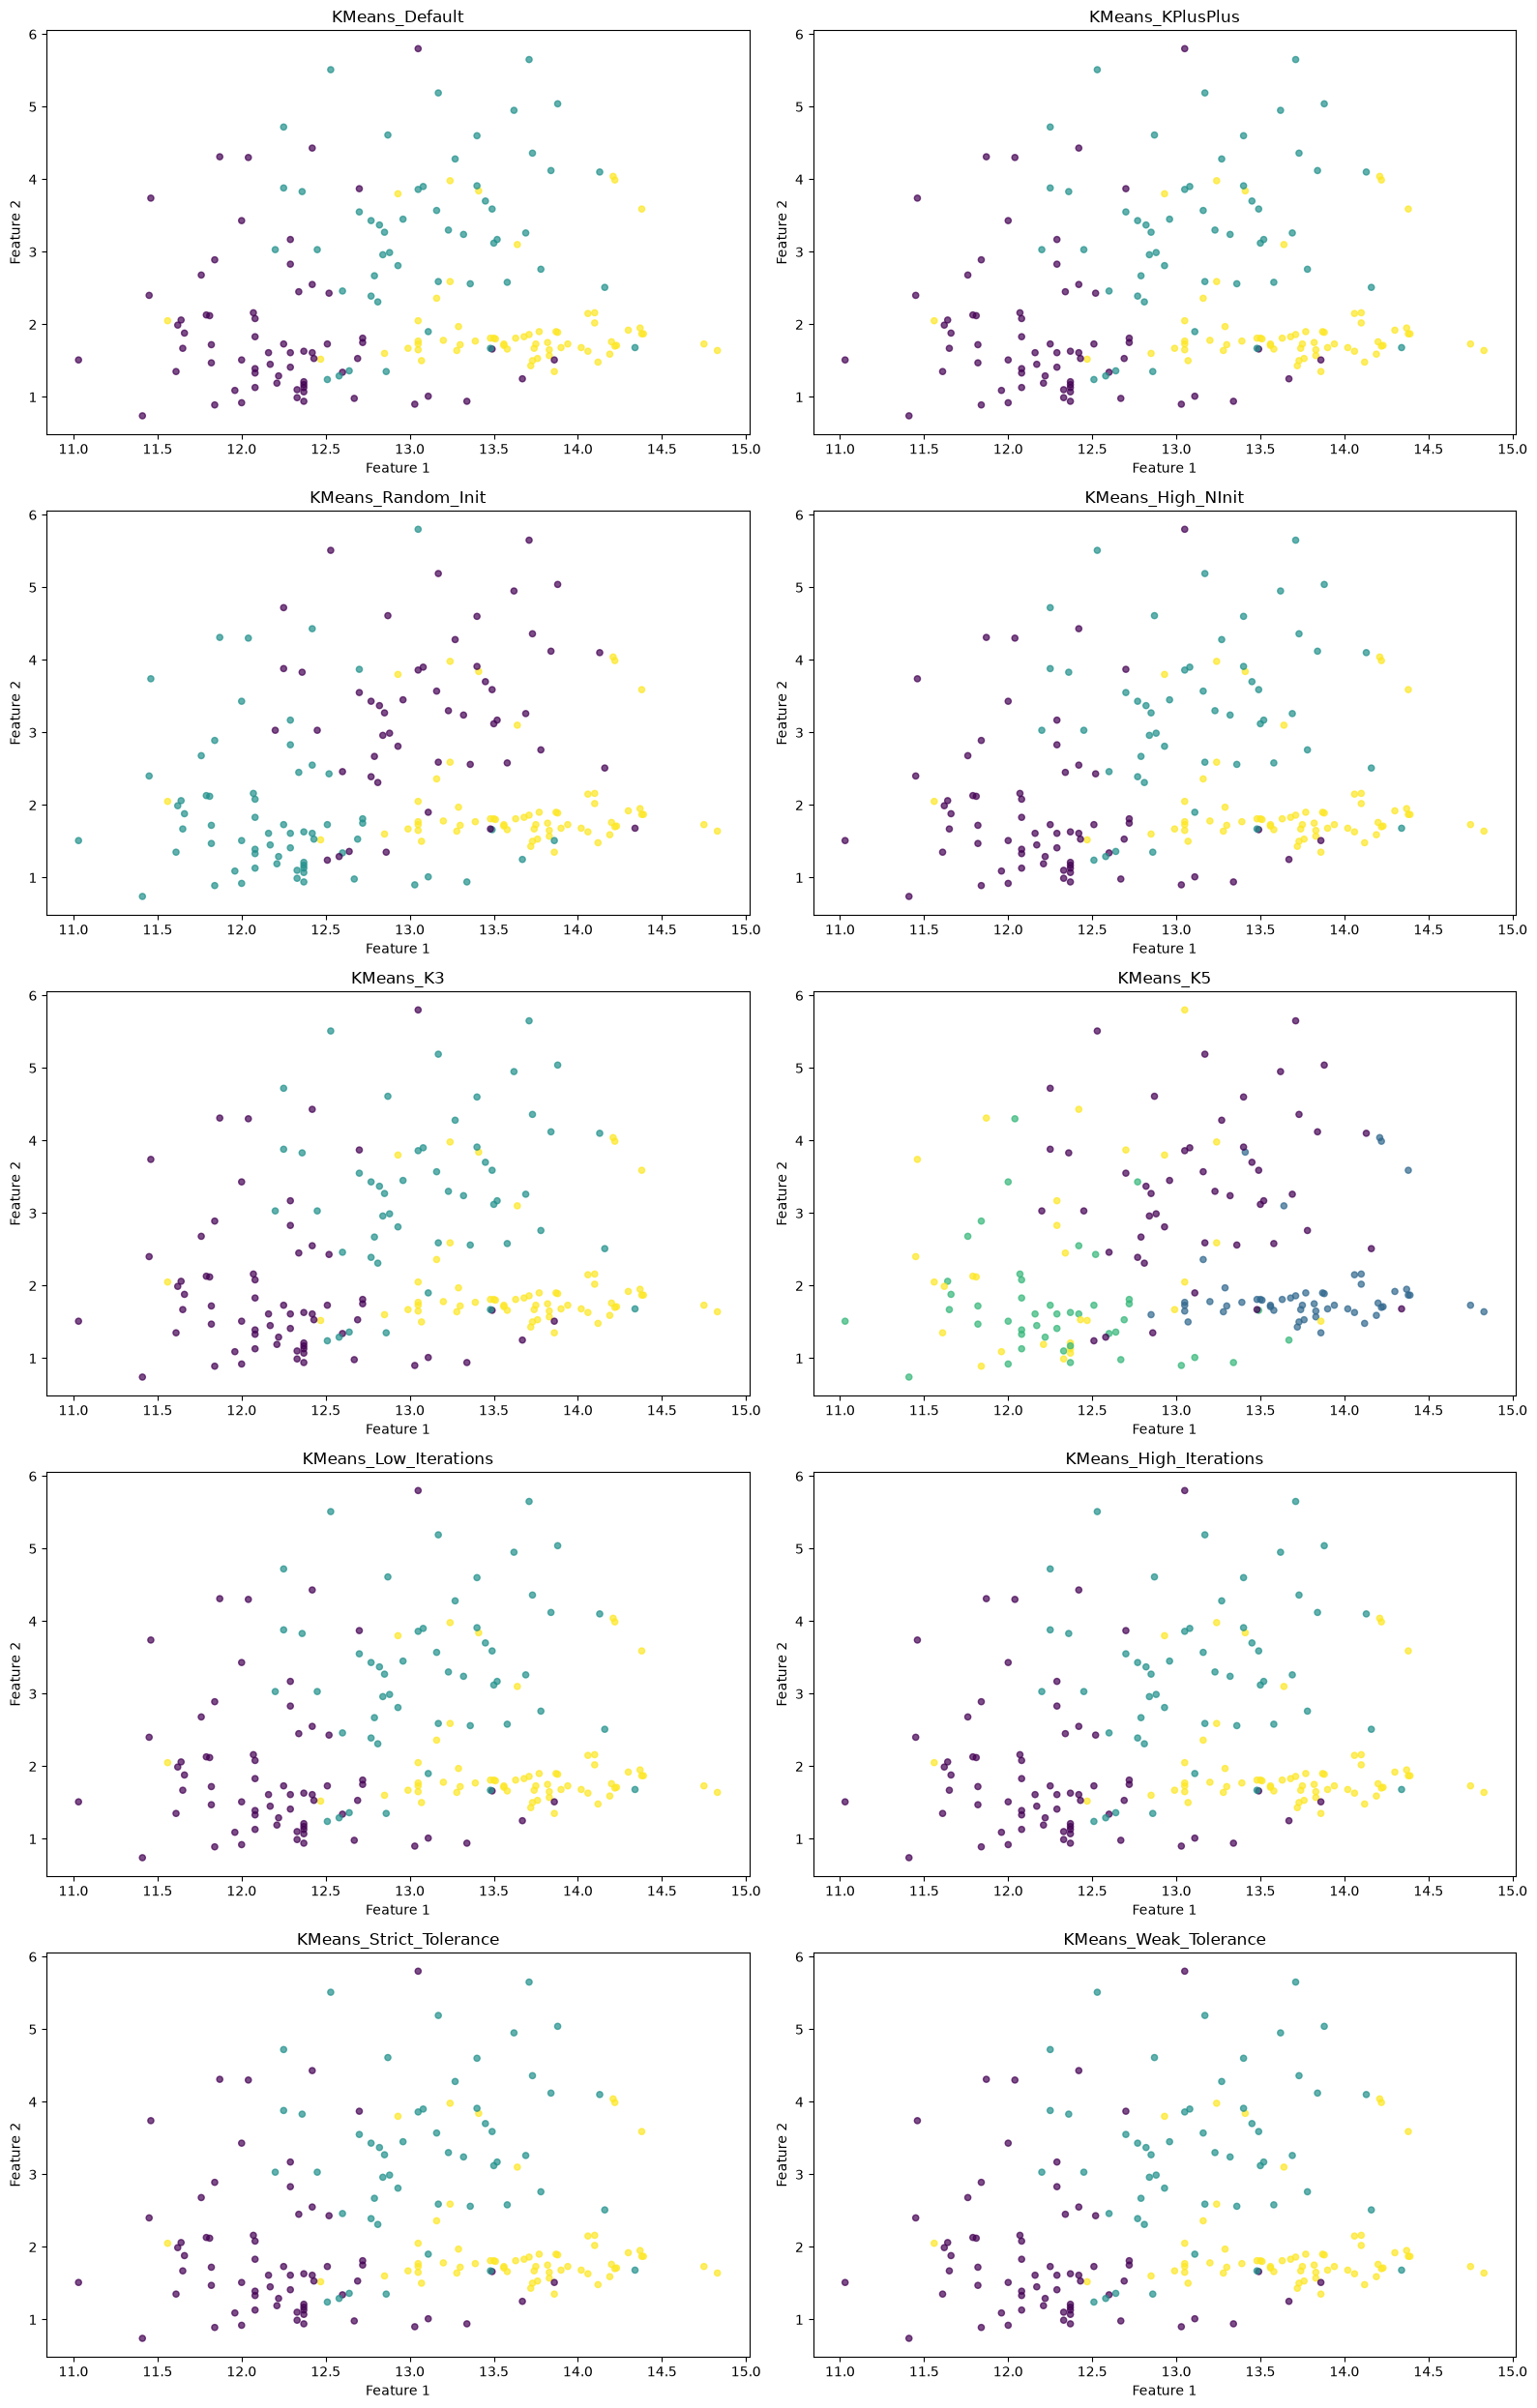

In [37]:
fig, axes = plt.subplots(5, 2, figsize=(16, 25))

axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):

    cluster_labels = model.predict(X)

    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=cluster_labels,
        cmap="viridis",
        s=20,
        alpha=0.7
    )

    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

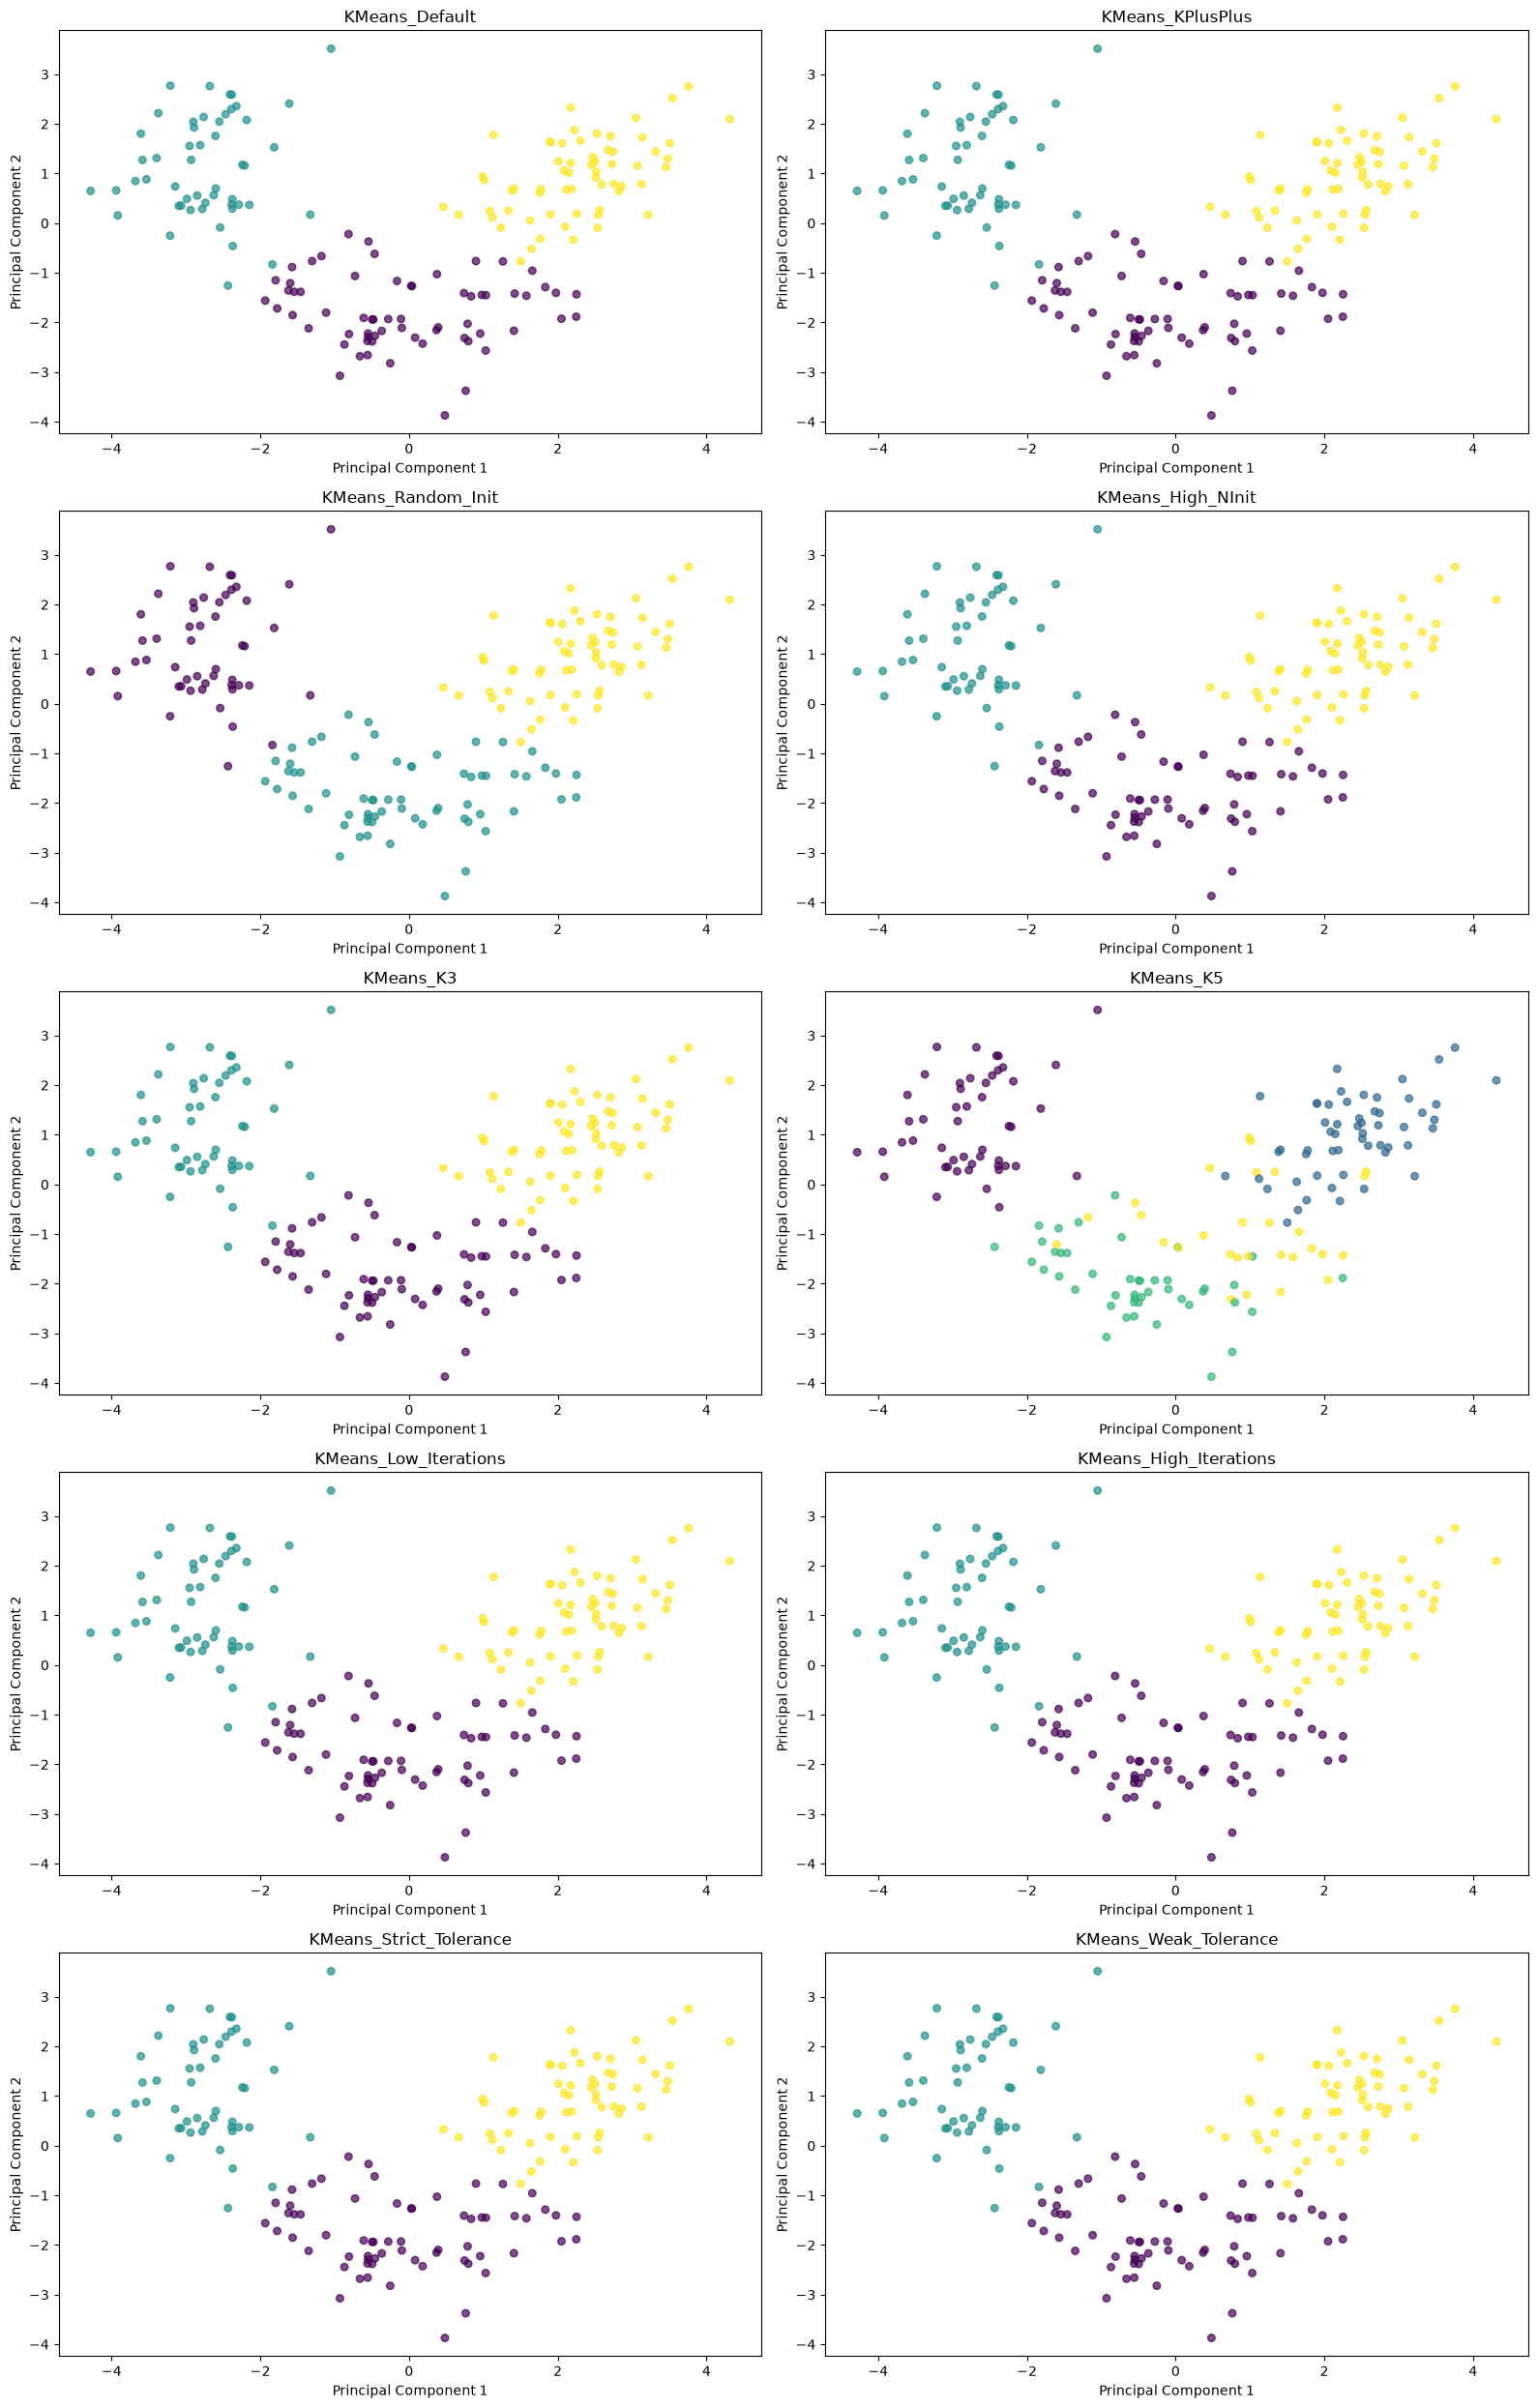

In [45]:
fig, axes = plt.subplots(5, 2, figsize=(16, 25))

axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):

    cluster_labels = model.predict(X)

    ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=cluster_labels,
        cmap="viridis",
        s=30,
        alpha=0.7
    )

    ax.set_title(name)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

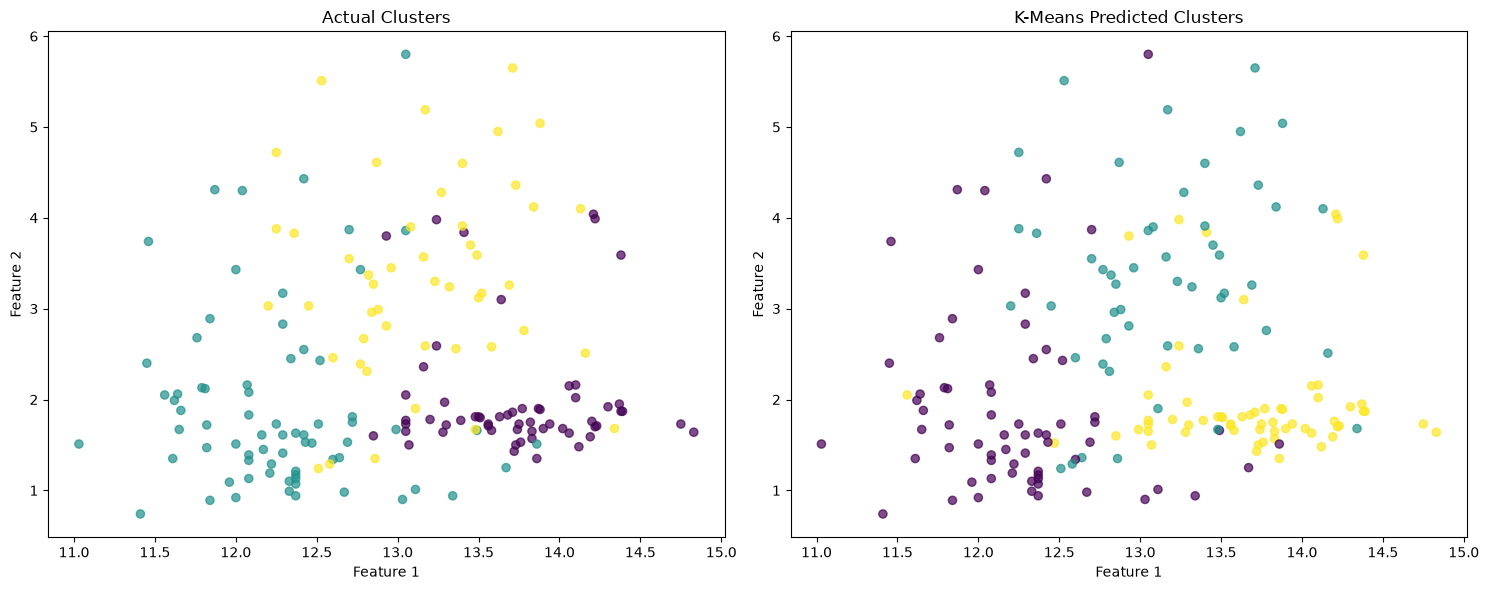

In [38]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Actual clusters
axes[0].scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="viridis",
    s=35,
    alpha=0.7
)

axes[0].set_title("Actual Clusters")

# Predicted clusters
axes[1].scatter(
    X[:, 0],
    X[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=35,
    alpha=0.7
)

axes[1].set_title("K-Means Predicted Clusters")

for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()


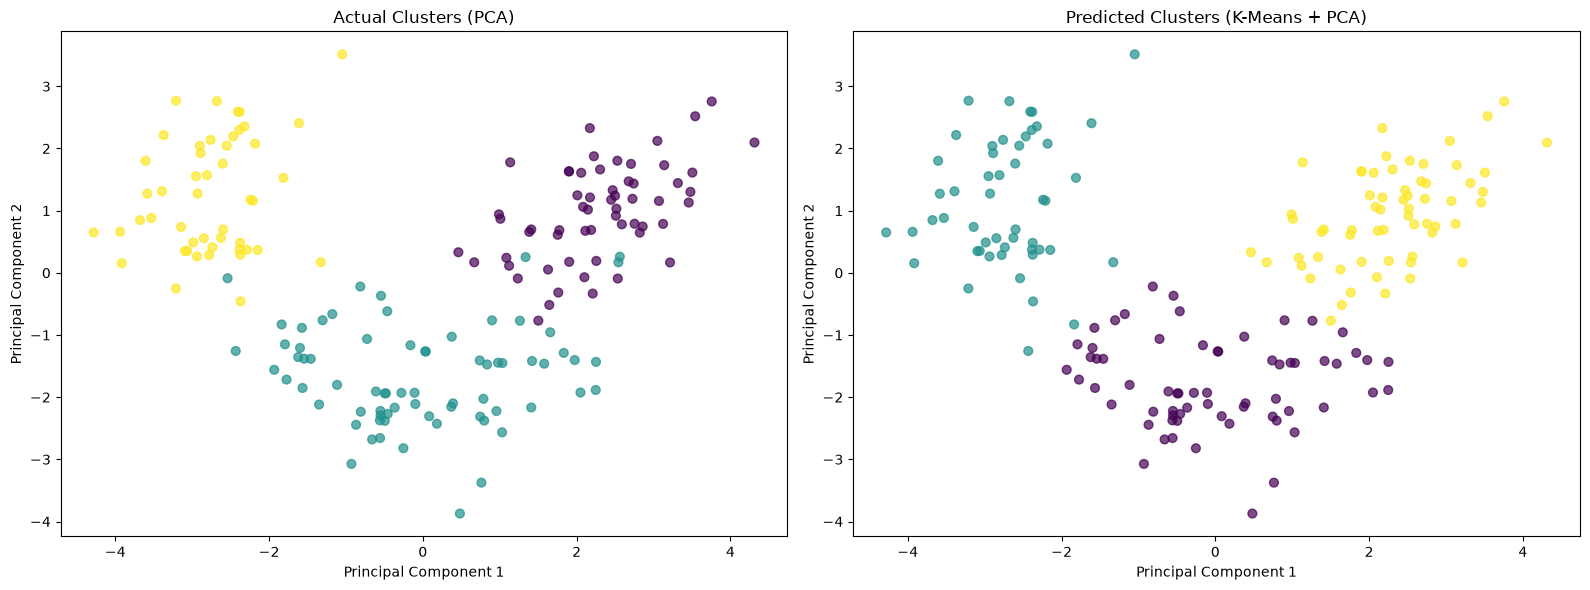

In [44]:
# Select your final K-Means model
final_model = models["KMeans_KPlusPlus"]

predicted_labels = final_model.predict(X)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Actual clusters
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    s=40,
    alpha=0.7
)

axes[0].set_title("Actual Clusters (PCA)")

# Predicted clusters
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=predicted_labels,
    cmap="viridis",
    s=40,
    alpha=0.7
)

axes[1].set_title("Predicted Clusters (K-Means + PCA)")

for ax in axes:
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [39]:

silhouette = silhouette_score(X_scaled, cluster_labels)

davies_bouldin = davies_bouldin_score(
    X_scaled, cluster_labels
)

calinski_harabasz = calinski_harabasz_score(
    X_scaled, cluster_labels
)

ari = adjusted_rand_score(y, cluster_labels)

evaluation_results = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Score",
        "Adjusted Rand Index"
    ],
    "Score": [
        silhouette,
        davies_bouldin,
        calinski_harabasz,
        ari
    ]
})

display(evaluation_results)


,Metric,Score
0,Silhouette Score,0.284859
1,Davies-Bouldin Index,1.389188
2,Calinski-Harabasz Score,70.940008
3,Adjusted Rand Index,0.897495


In [40]:
# Fit PCA on scaled features
pca = PCA(n_components=2)

X_pca = pca.fit_transform(
    StandardScaler().fit_transform(X)
)

print("Original dimensions:", X.shape)
print("PCA dimensions:", X_pca.shape)

print(
    "Total variance explained:",
    pca.explained_variance_ratio_.sum()
)

Original dimensions: (178, 13)
PCA dimensions: (178, 2)
Total variance explained: 0.5540633835693528


# K-Means Clustering

**Fundamentals, Mathematics, Evaluation Metrics and Implementation in Python**

This notebook covers K-Means clustering from first principles: the core concepts, the underlying mathematics, assumptions and limitations, evaluation metrics, hyperparameters, a practical scikit-learn implementation, and applied scenarios.

## Contents

1. K-Means Clustering Fundamentals
2. Mathematical and Algorithmic Understanding
3. Assumptions and Limitations
4. Clustering Evaluation Metrics
5. Overfitting, Underfitting and Model Selection
6. Practical Python and Scikit-learn Implementation
7. Practical Data Science Problems
8. Interview Questions: Real-World Scenarios
9. Quick Revision Sheet
10. Important Formulas
11. Key Conceptual Distinctions

---

## 1. K-Means Clustering Fundamentals

### Q1. What is K-Means Clustering?

K-Means is an unsupervised machine learning algorithm used to group observations into K clusters based on their similarity.

It works by assigning observations to the nearest cluster centroid and iteratively updating the centroids until the algorithm converges.

The objective is to minimise the within-cluster sum of squared distances (Inertia).

### Q2. Why is K-Means called an unsupervised learning algorithm?

Because it does not require predefined target labels to learn patterns from the data.

It discovers groups based on the features provided to the algorithm.

For example, a retail company can use K-Means to segment customers based on:

- Purchase frequency.
- Average spending.
- Product preferences.
- Customer engagement.

The algorithm discovers customer segments without knowing their categories beforehand.

### Q3. What does K represent in K-Means?

K represents the number of clusters we want the algorithm to create.

For example:

- K = 2: Creates two clusters.
- K = 3: Creates three clusters.
- K = 5: Creates five clusters.

K must be specified before training the standard K-Means algorithm.

### Q4. What is a centroid?

A centroid is the centre of a cluster, calculated as the mean of all observations assigned to that cluster.

For a cluster containing $n$ observations:

$$
\mu = \frac{1}{n}\sum_{i=1}^{n} x_i
$$

Where:

- $\mu$: Cluster centroid.
- $n$: Number of observations in the cluster.
- $x_i$: Individual observation.

The centroid represents the average position of the observations belonging to that cluster.

### Q5. How does K-Means work?

K-Means generally follows these steps:

1. Specify the number of clusters (K).
2. Initialise K centroids.
3. Calculate the distance between each observation and every centroid.
4. Assign each observation to its nearest centroid.
5. Recalculate the centroids using the mean of their assigned observations.
6. Repeat the assignment and centroid-update steps.
7. Stop when the algorithm converges or reaches the maximum number of iterations.

### Q6. What is the difference between clustering and classification?

| Clustering | Classification |
|---|---|
| Unsupervised learning | Supervised learning |
| Does not require labelled training data | Requires labelled training data |
| Discovers groups in data | Predicts predefined classes |
| Finds hidden patterns | Learns existing patterns from labelled examples |
| Example: K-Means | Example: Logistic Regression |

### Q7. Can clustering be used for classification?

Clustering can support a classification workflow, but clustering itself is not a classification algorithm.

For example:

1. Use K-Means to identify customer segments.
2. Analyse and assign meaningful labels to those segments.
3. Train a supervised classifier using the resulting labelled observations.
4. Use the classifier to assign future observations to predefined categories.

Alternatively, K-Means can assign new observations to the nearest existing centroid using `predict()`.

However, this is cluster assignment, not supervised classification.

### Q8. What is the difference between K-Means and K-Nearest Neighbors (KNN)?

| K-Means | KNN |
|---|---|
| Unsupervised algorithm | Supervised algorithm |
| Used for clustering | Used for classification and regression |
| Groups similar observations | Uses nearby labelled observations |
| Learns cluster centroids | Stores training observations |
| Requires K clusters | Requires K neighbours |

Despite having similar names, they solve different problems.

---

## 2. Mathematical and Algorithmic Understanding

### Q9. What is the objective function of K-Means?

K-Means minimises the Within-Cluster Sum of Squares (WCSS), also commonly called Inertia in scikit-learn.

$$
J = \sum_{i=1}^{K}\sum_{x \in C_i} \lVert x - \mu_i \rVert^2
$$

Where:

- $K$: Number of clusters.
- $C_i$: Observations assigned to cluster $i$.
- $x$: Individual observation.
- $\mu_i$: Centroid of cluster $i$.
- $\lVert x - \mu_i \rVert^2$: Squared Euclidean distance from the observation to its centroid.

The objective is to minimise the total squared distance between observations and their assigned centroids.

### Q10. What is Inertia in K-Means?

Inertia measures the sum of squared Euclidean distances between each observation and its assigned cluster centroid.

In simple terms, it tells us how compact the clusters are.

- **Lower Inertia:** Observations are generally closer to their centroids.
- **Higher Inertia:** Observations are generally farther from their centroids.

However, lower Inertia does not automatically indicate a better clustering model because Inertia generally decreases as K increases.

### Q11. How is Inertia calculated?

Suppose a cluster contains four observations with distances from its centroid of:

| Observation | Distance | Squared distance |
|---|---|---|
| A | 2 | 4 |
| B | 3 | 9 |
| C | 1 | 1 |
| D | 4 | 16 |

The cluster's Inertia is:

$$
4 + 9 + 1 + 16 = 30
$$

We calculate this for every cluster and add the results to obtain the total Inertia.

In scikit-learn:

```python
model.inertia_
```

### Q12. What is the Elbow Method?

The Elbow Method is a technique used to estimate the appropriate number of clusters in K-Means.

It works by:

1. Training K-Means models with different values of K.
2. Recording the Inertia for each model.
3. Plotting K against Inertia.
4. Identifying the point where the reduction in Inertia starts becoming relatively small.

This point is called the **elbow**.

The elbow represents a point of diminishing returns, where adding more clusters provides relatively little improvement in reducing within-cluster variation.

### Q13. Why does Inertia decrease when K increases?

Increasing K provides more centroids, allowing observations to be assigned to more specific groups.

Consequently, observations generally become closer to their assigned centroids.

Inertia therefore generally decreases or stays the same as K increases.

In the extreme case, if every observation has its own cluster:

$$
K = n \;\Rightarrow\; \text{Inertia} = 0
$$

This does not mean the clustering is meaningful.

### Q14. What are the limitations of the Elbow Method?

- The elbow is not always clearly visible.
- Different people may interpret the elbow differently.
- It does not directly measure separation between clusters.
- It can suggest multiple reasonable values of K.
- It does not guarantee the optimal number of clusters.

Therefore, it should be used alongside other evaluation techniques, such as Silhouette Score.

### Q15. What is the difference between WCSS and BCSS?

**Within-Cluster Sum of Squares (WCSS):**

Measures the variation within individual clusters, i.e. how far observations are from their respective cluster centroids.

$$
\text{WCSS} = \sum_{i=1}^{K}\sum_{x \in C_i} \lVert x - \mu_i \rVert^2
$$

**Between-Cluster Sum of Squares (BCSS):**

Measures the variation between cluster centroids and the overall dataset centroid, weighted by cluster sizes.

$$
\text{BCSS} = \sum_{i=1}^{K} n_i \lVert \mu_i - \mu \rVert^2
$$

Where $n_i$ is the number of observations in cluster $i$ and $\mu$ is the overall dataset centroid.

For a dataset of $n$ observations:

$$
\text{TSS} = \text{WCSS} + \text{BCSS}
$$

Where TSS is the total sum of squares around the overall mean, using the same feature representation.

### Q16. What is the K-Means++ initialisation method?

K-Means++ is an improved centroid initialisation technique designed to spread initial centroids apart.

Its general procedure:

1. Select the first centroid randomly from the observations.
2. Calculate the squared distance of every observation to its nearest selected centroid.
3. Select the next centroid with probability proportional to that squared distance.
4. Repeat until K centroids have been selected.

It reduces the likelihood of poor initial centroid placement compared with basic random initialisation.

In scikit-learn:

```python
KMeans(
    n_clusters=4,
    init="k-means++"
)
```

### Q17. What is the difference between K-Means++ and Random Initialisation?

| K-Means++ | Random |
|---|---|
| Selects initial centroids using distance-based probabilities | Selects initial centroids randomly |
| Encourages centroids to be spread apart | May select centroids close together |
| Often provides better initialisation | Can produce poor initialisation |
| Default in scikit-learn | Alternative initialisation method |

### Q18. What is convergence in K-Means?

Convergence occurs when the algorithm reaches a point where further iterations no longer produce significant changes.

In practice, scikit-learn can stop when:

- Centroid movements fall below the specified tolerance.
- The maximum number of iterations is reached.

### Q19. Does K-Means guarantee a global optimum?

No.

K-Means uses an iterative optimisation procedure that can converge to a local minimum.

The final result depends partly on the initial centroid positions.

Running the algorithm multiple times with different initialisations can help find a better solution.

### Q20. What is the difference between Batch K-Means and Mini-Batch K-Means?

| K-Means | Mini-Batch K-Means |
|---|---|
| Uses the full dataset during centroid updates | Uses small random batches |
| Can be computationally expensive on large datasets | Generally more computationally efficient |
| Performs full-data updates | Performs approximate incremental updates |
| Suitable for small and medium datasets | Useful for large datasets |

Scikit-learn provides `MiniBatchKMeans`:

```python
from sklearn.cluster import MiniBatchKMeans
```

### Q21. How does K-Means assign a new observation to a cluster?

After training, K-Means calculates the distance between the new observation and each learned centroid.

It assigns the observation to the cluster with the nearest centroid.

Scikit-learn:

```python
new_predictions = model.predict(X_new)
```

This does not retrain the model or change the existing centroids.

---

## 3. Assumptions and Limitations

### Q22. What are the main assumptions of K-Means?

K-Means works particularly well when:

| Assumption / Data characteristic | Meaning |
|---|---|
| Compact clusters | Observations are relatively close to their centroids |
| Convex cluster shapes | Clusters are approximately convex, often roughly spherical |
| Similar cluster sizes | Clusters have reasonably comparable sizes |
| Similar densities | Clusters have reasonably comparable densities |
| Meaningful distance | Euclidean distance reflects similarity between observations |
| Numerical features | Features can be represented meaningfully as numerical values |

These are suitability conditions rather than strict statistical assumptions.

### Q23. Why is feature scaling important in K-Means?

K-Means commonly uses Euclidean distance to measure similarity.

Suppose a dataset contains:

- Age: 18–60.
- Annual income: £10,000–£100,000.

Income has a much larger numerical scale and can dominate distance calculations.

Standardisation helps make features more comparable.

**Standardisation:**

$$
z = \frac{x - \mu}{\sigma}
$$

Scikit-learn:

```python
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
```

### Q24. What happens if you don't scale your features?

Features with larger numerical ranges can dominate distance calculations.

This can result in clusters being formed primarily around those features rather than considering all features appropriately.

However, scaling should depend on the dataset and the meaning of the features.

### Q25. Why is K-Means sensitive to outliers?

K-Means calculates centroids using the arithmetic mean.

Extreme observations can significantly influence the mean and move the centroids away from the main concentration of observations.

This can result in poor cluster assignments.

Possible solutions:

- Investigate and handle genuine data errors.
- Use robust preprocessing.
- Consider alternative clustering algorithms.
- Investigate K-Medoids when robustness to outliers is important.

### Q26. Why does K-Means struggle with non-spherical clusters?

K-Means assigns observations based on their distance to centroids.

Its resulting decision boundaries between centroids are linear Voronoi boundaries.

Consequently, it tends to favour compact, convex clusters rather than arbitrarily shaped clusters.

For example, it struggles with:

- Crescent-shaped clusters.
- Concentric circular clusters.
- Highly elongated clusters.

Algorithms such as DBSCAN or Spectral Clustering can be more suitable for these structures.

### Q27. Can K-Means work with categorical data?

Standard K-Means is not directly suitable for purely categorical features because its centroid calculation relies on numerical means and Euclidean distances.

Possible alternatives:

- K-Modes for categorical data.
- K-Prototypes for mixed numerical and categorical data.
- Appropriate encoding and distance-based approaches, depending on the problem.

One-Hot Encoding alone does not automatically make K-Means appropriate for every categorical dataset.

### Q28. What happens if K is too small?

- Different natural groups may be merged.
- Clusters may become overly broad.
- Important differences between observations may be lost.
- Inertia may remain relatively high.

This can result in **under-segmentation**.

### Q29. What happens if K is too large?

- Natural groups may be divided unnecessarily.
- Clusters may become very small.
- The model may capture minor variations rather than meaningful patterns.
- Inertia decreases, but interpretability can suffer.

This can result in **over-segmentation**.

### Q30. What happens if two clusters have very different densities?

K-Means may struggle to identify both groups accurately because it favours compact clusters with reasonably similar characteristics.

A dense cluster and a sparse cluster may not be represented appropriately by centroid-based assignments.

DBSCAN and other density-aware methods may be more suitable, depending on the density structure.

### Q31. What is the difference between K-Means and DBSCAN?

| K-Means | DBSCAN |
|---|---|
| Centroid-based clustering | Density-based clustering |
| Requires K beforehand | Does not require K |
| Assigns observations to clusters | Can identify noise observations |
| Struggles with non-convex shapes | Can identify arbitrarily shaped clusters |
| Sensitive to outliers | Can explicitly identify noise |
| Requires centroid-based distance calculations | Uses neighbourhood density |

### Q32. What is the difference between K-Means and Agglomerative Clustering?

| K-Means | Agglomerative |
|---|---|
| Centroid-based | Hierarchical |
| Divides data into K clusters | Builds a hierarchy of clusters |
| Updates centroids iteratively | Merges clusters iteratively |
| Generally computationally efficient | Can be computationally expensive |
| Does not produce a hierarchy | Can produce a dendrogram |

---

## 4. Clustering Evaluation Metrics

Unlike supervised learning, clustering does not always have ground-truth labels.

Therefore, clustering evaluation uses two main categories of metrics:

- **Internal evaluation:** Evaluates the quality of clusters using the feature data and predicted cluster assignments.
- **External evaluation:** Compares predicted clusters against actual labels, when available.

### Q33. What are the main evaluation metrics for K-Means?

| Metric | What it measures | Better value |
|---|---|---|
| Inertia | Within-cluster squared distances | Lower |
| Silhouette Score | Cluster cohesion and separation | Higher |
| Davies-Bouldin Index | Similarity between clusters | Lower |
| Calinski-Harabasz Index | Between-cluster dispersion relative to within-cluster dispersion | Higher |
| Adjusted Rand Index (ARI) | Agreement with actual labels | Higher |

### Q34. What is the Silhouette Score?

Silhouette Score measures how well an observation fits within its assigned cluster compared with the nearest neighbouring cluster.

It considers:

- **Cohesion:** How close an observation is to other observations in its own cluster.
- **Separation:** How far an observation is from observations in the nearest other cluster.

**Formula:**

$$
S(i) = \frac{b(i) - a(i)}{\max\big(a(i),\, b(i)\big)}
$$

Where:

- $a(i)$: Average distance between observation $i$ and other observations in its own cluster.
- $b(i)$: Lowest average distance between observation $i$ and observations in another cluster.

**Interpretation:**

| Silhouette Score | Interpretation |
|---|---|
| Close to +1 | Well-separated clusters |
| Close to 0 | Overlapping clusters |
| Close to -1 | Potentially incorrect assignments |

The overall Silhouette Score is the average across all observations.

### Q35. What is the Davies-Bouldin Index?

Davies-Bouldin Index measures the average similarity between each cluster and its most similar neighbouring cluster.

It considers:

- Within-cluster dispersion.
- Between-cluster separation.

A lower score indicates better-defined, more separated clusters.

A score of zero indicates perfectly separated, zero-dispersion clusters under the metric's definition.

### Q36. What is the Calinski-Harabasz Index?

Calinski-Harabasz Index measures the ratio of between-cluster dispersion to within-cluster dispersion, adjusted for the number of clusters and observations.

**Formula:**

$$
\text{CH} = \frac{B_k / (k - 1)}{W_k / (n - k)}
$$

Where:

- $B_k$: Between-cluster dispersion.
- $W_k$: Within-cluster dispersion.
- $k$: Number of clusters.
- $n$: Number of observations.

A higher score generally indicates more compact and well-separated clusters.

### Q37. What is Adjusted Rand Index (ARI)?

ARI measures the similarity between predicted cluster assignments and actual ground-truth labels.

It compares pairs of observations and checks whether they are grouped consistently.

Unlike Inertia and Silhouette Score, ARI requires actual labels.

**Interpretation:**

| ARI | Interpretation |
|---|---|
| 1 | Perfect agreement |
| Around 0 | Agreement comparable to random assignment |
| Negative | Agreement worse than the expected random baseline |

ARI is adjusted for chance and does not require predicted cluster IDs to match actual class IDs.

### Q38. What is the difference between Silhouette Score and Inertia?

| Inertia | Silhouette Score |
|---|---|
| Measures within-cluster compactness | Measures compactness and separation |
| Considers distance to own centroid | Considers average distances to own and neighbouring clusters |
| Generally decreases with increasing K | Can increase or decrease with K |
| No fixed upper bound | Ranges from -1 to +1 |
| Lower is preferred | Higher is preferred |

### Q39. Can we use Accuracy, Precision, Recall and F1-score for clustering?

Not directly.

These metrics require predicted labels that correspond to known ground-truth classes.

K-Means produces arbitrary cluster IDs rather than predefined class predictions.

If actual labels are available, external clustering metrics such as ARI, Normalised Mutual Information (NMI) and homogeneity can be used.

### Q40. Can a model have low Inertia but a poor Silhouette Score?

Yes.

Inertia only measures how close observations are to their assigned centroids.

It does not directly measure how well-separated different clusters are.

For example, a model with too many clusters might have low Inertia but still produce fragmented or poorly separated groups.

### Q41. What is the difference between internal and external clustering evaluation?

| Internal Evaluation | External Evaluation |
|---|---|
| Does not require actual labels | Requires actual labels |
| Evaluates cluster structure | Evaluates agreement with known classes |
| Examples: Silhouette, DBI, CH | Examples: ARI, NMI, Homogeneity |
| Useful when labels are unavailable | Useful when ground truth exists |

### Q42. Should we always select the model with the highest Silhouette Score?

No.

A higher Silhouette Score is generally desirable, but it should not be the only selection criterion.

Consider:

- Whether the clusters are meaningful.
- Whether the cluster sizes are reasonable.
- Whether the segmentation is useful for the business problem.
- Whether the model is stable across initialisations.
- Whether the model has too many or too few clusters.

---

## 5. Overfitting, Underfitting and Model Selection

### Q43. Can K-Means overfit?

Yes, although overfitting in clustering is not exactly the same as in supervised learning.

When K is excessively large, K-Means can create many small clusters that capture minor variations or noise rather than meaningful underlying groups.

This can result in over-segmentation and poor interpretability.

### Q44. What is underfitting in K-Means?

Underfitting occurs when the number of clusters is too small to represent the underlying structure of the dataset.

For example, if a dataset naturally contains four distinct groups but we use K = 2, multiple groups may be merged.

### Q45. How do you select the optimal number of clusters?

There is no universally correct method.

Common approaches include:

1. Elbow Method.
2. Silhouette Analysis.
3. Calinski-Harabasz Index.
4. Davies-Bouldin Index.
5. Domain knowledge.
6. Cluster stability analysis.

The final selection should consider both mathematical evaluation and practical usefulness.

### Q46. What is Silhouette Analysis?

Silhouette Analysis evaluates how well individual observations fit within their assigned clusters.

It can also help identify:

- Poorly assigned observations.
- Overlapping clusters.
- Clusters with different levels of cohesion.
- Whether a particular K produces meaningful groupings.

It is often visualised using silhouette plots.

### Q47. What is cluster stability?

Cluster stability refers to how consistently a clustering algorithm identifies similar groups when the data or initialisation changes.

For example:

1. Train K-Means on the original dataset.
2. Train it again using different random initialisations or resampled observations.
3. Compare the resulting cluster assignments.
4. Check whether the identified groups remain consistent.

ARI or other clustering similarity measures can help assess stability.

### Q48. What is the effect of increasing `n_init`?

`n_init` specifies the number of independent centroid initialisation runs.

K-Means executes multiple runs and retains the best solution according to Inertia.

Increasing `n_init`:

- Gives the algorithm more opportunities to find a better solution.
- Can reduce sensitivity to poor initialisation.
- Can improve solution stability.
- Increases computational cost.

### Q49. What happens when the convergence tolerance is too high?

A higher tolerance makes the convergence condition less strict.

The algorithm may stop earlier, even when further centroid adjustments could improve the solution.

This can result in less refined clustering.

### Q50. What happens when the maximum number of iterations is too low?

The algorithm may stop before reaching convergence.

Consequently, centroid positions and cluster assignments may not have stabilised.

Increasing `max_iter` gives the algorithm more opportunities to converge, although it does not guarantee a better solution if the algorithm is already converged.

### Q51. What is the difference between `n_init` and `max_iter`?

| Parameter | Purpose |
|---|---|
| `n_init` | Number of independent initialisation runs |
| `max_iter` | Maximum iterations allowed within each run |

For example:

```python
KMeans(
    n_clusters=4,
    n_init=10,
    max_iter=300
)
```

This allows 10 initialisation runs, each with a maximum of 300 iterations.

---

## 6. Practical Python and Scikit-learn Implementation

### Q52. How do you import K-Means from scikit-learn?

```python
from sklearn.cluster import KMeans
```

### Q53. How do you train a K-Means model?

```python
from sklearn.cluster import KMeans

model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

model.fit(X)
cluster_labels = model.labels_
```

### Q54. What is the difference between `fit()`, `predict()` and `fit_predict()`?

| Method | Purpose |
|---|---|
| `fit()` | Learns cluster centroids from the dataset |
| `predict()` | Assigns new observations to existing clusters |
| `fit_predict()` | Fits the model and returns cluster assignments |

Example:

```python
model.fit(X_train)
y_pred = model.predict(X_test)
```

Alternatively:

```python
cluster_labels = model.fit_predict(X)
```

### Q55. How do you access cluster centroids?

```python
print(model.cluster_centers_)
```

This returns the coordinates of the learned centroids.

For a dataset with two features and four clusters, the output contains four centroid coordinates, each having two values.

### Q56. How do you calculate Inertia?

```python
print("Inertia:", model.inertia_)
```

This returns the sum of squared distances between observations and their assigned centroids.

### Q57. What are the important hyperparameters of scikit-learn `KMeans`?

```python
KMeans(
    n_clusters=8,
    init="k-means++",
    n_init="auto",
    max_iter=300,
    tol=1e-4,
    random_state=None,
    algorithm="lloyd"
)
```

| Parameter | Purpose |
|---|---|
| `n_clusters` | Number of clusters |
| `init` | Centroid initialisation method |
| `n_init` | Number of independent initialisation runs |
| `max_iter` | Maximum iterations per run |
| `tol` | Relative tolerance for convergence |
| `random_state` | Controls random initialisation |
| `algorithm` | Algorithm used for optimisation |

### Q58. What does `n_clusters` do?

Specifies how many clusters the algorithm should create.

Example:

```python
KMeans(n_clusters=4)
```

The model will identify four clusters.

### Q59. What does `init` do?

Specifies how initial centroids are selected.

Available options:

- `"k-means++"`: Distance-based initialisation.
- `"random"`: Randomly selects observations as initial centroids.
- An array: Allows users to provide their own initial centroid positions.

### Q60. What does `n_init` do?

Specifies how many times K-Means should run with different initial centroid positions.

Example:

```python
KMeans(
    n_clusters=4,
    n_init=20,
    random_state=42
)
```

The best run according to Inertia is retained.

In current scikit-learn versions, the default is `"auto"`, which selects the number of initialisations based on the initialisation method.

### Q61. What does `max_iter` do?

Controls the maximum number of iterations for each initialisation run.

Example:

```python
KMeans(
    n_clusters=4,
    max_iter=500
)
```

The algorithm can perform up to 500 iterations per run.

### Q62. What does `tol` do?

Controls the convergence tolerance.

Example:

```python
KMeans(
    n_clusters=4,
    tol=1e-6
)
```

A smaller tolerance generally requires more precise convergence, while a larger tolerance allows earlier termination.

### Q63. What does `random_state` do?

Controls the random number generation used during centroid initialisation.

Using the same `random_state` makes results reproducible under the same data and software configuration.

### Q64. What does `algorithm` do?

Specifies the underlying optimisation algorithm.

Available options:

- `"lloyd"`: Standard Lloyd's K-Means algorithm.
- `"elkan"`: Uses the Elkan variation, which can accelerate clustering for some datasets by exploiting the triangle inequality.

Lloyd's algorithm is the default.

### Q65. How do you create a Pipeline for K-Means?

A Pipeline allows preprocessing and clustering to be performed together.

```python
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KMeans(
        n_clusters=4,
        init="k-means++",
        n_init=10,
        random_state=42
    ))
])

cluster_labels = model.fit_predict(X)
```

The scaler is fitted on the input data before K-Means learns its centroids.

### Q66. How do you evaluate a K-Means model?

```python
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print(
    "Silhouette Score:",
    silhouette_score(X_scaled, cluster_labels)
)

print(
    "Davies-Bouldin Index:",
    davies_bouldin_score(X_scaled, cluster_labels)
)

print(
    "Calinski-Harabasz Score:",
    calinski_harabasz_score(X_scaled, cluster_labels)
)
```

If ground-truth labels are available:

```python
from sklearn.metrics import adjusted_rand_score

print(
    "ARI:",
    adjusted_rand_score(y_true, cluster_labels)
)
```

### Q67. How do you visualise K-Means clusters?

```python
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=40
)

plt.scatter(
    model.named_steps["model"].cluster_centers_[:, 0],
    model.named_steps["model"].cluster_centers_[:, 1],
    marker="X",
    color="red",
    s=200,
    label="Centroids"
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()
```

This example assumes the model is a Pipeline with a `StandardScaler` followed by K-Means, and that `X_scaled` is the transformed dataset.

### Q68. Can K-Means work with missing values?

Standard scikit-learn K-Means does not directly support `NaN` values.

You should handle missing values before training.

Possible approaches:

- Mean imputation.
- Median imputation.
- KNN imputation.
- Removing observations when appropriate.

Example:

```python
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)
```

Fit preprocessing transformations appropriately, particularly when evaluating generalisation on held-out observations.

---

## 7. Practical Data Science Problems

### Q69. You have a dataset containing missing values. How would you handle them before applying K-Means?

Possible approach:

1. Identify missing values using `isnull()`.
2. Understand why values are missing.
3. Check the percentage of missing values per feature.
4. Decide whether to remove or impute observations.
5. Use mean or median imputation for numerical variables when appropriate.
6. Apply preprocessing before clustering.

Example:

```python
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)
```

### Q70. Your dataset contains categorical variables. How would you handle them?

Standard K-Means requires numerical features.

Possible approaches:

- One-Hot Encoding for nominal categorical variables, when Euclidean distance on the resulting representation is meaningful.
- Ordinal Encoding for genuinely ordered categories.
- K-Modes for purely categorical data.
- K-Prototypes for mixed numerical and categorical data.

Be careful: encoding categorical features can introduce artificial distance relationships.

### Q71. Your dataset contains outliers. What would you do?

1. Identify outliers using boxplots, IQR or domain knowledge.
2. Investigate whether they are genuine observations or data errors.
3. Understand their impact on centroid positions.
4. Consider appropriate transformations or robust preprocessing.
5. Evaluate whether K-Means is suitable.

Do not automatically remove every outlier.

### Q72. Your numerical features have very different scales. What would you do?

Use feature scaling where appropriate.

**Standardisation:**

$$
z = \frac{x - \mu}{\sigma}
$$

Example:

```python
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
```

Standardisation ensures that features with larger numerical ranges do not automatically dominate Euclidean distance calculations.

### Q73. You have 100 features. Can you still apply K-Means?

Yes.

K-Means can handle high-dimensional numerical data, but there are some considerations:

- Distance calculations can become less informative in high dimensions.
- Irrelevant features can negatively affect clustering.
- Computational requirements increase.
- Visualisation becomes more difficult.

Possible approaches:

- Feature selection.
- PCA.
- Feature scaling.
- Domain-based feature engineering.

### Q74. How would you use PCA with K-Means?

PCA can reduce the dimensionality of a dataset while preserving as much variance as possible.

A possible workflow:

1. Standardise the dataset.
2. Apply PCA.
3. Select an appropriate number of principal components.
4. Apply K-Means to the transformed data.
5. Evaluate the resulting clusters.

Example:

```python
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
    ("kmeans", KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

cluster_labels = model.fit_predict(X)
```

**Important:** PCA preserves directions of high variance, not necessarily directions that best separate clusters.

### Q75. Your Elbow Method graph does not show a clear elbow. What would you do?

Possible approaches:

- Calculate Silhouette Scores for different K values.
- Compare Davies-Bouldin and Calinski-Harabasz scores.
- Investigate cluster stability.
- Visualise the clusters using PCA.
- Use domain knowledge to identify meaningful segmentation.
- Compare alternative clustering algorithms.

A clear elbow is not guaranteed to exist.

### Q76. You have two features that are highly correlated. What would you do?

Investigate whether both features provide useful and distinct information.

Possible approaches:

- Remove redundant features.
- Use PCA.
- Perform feature selection.
- Retain both if they provide meaningful information for the clustering objective.

Highly correlated features can effectively give the same underlying information additional influence in Euclidean distance calculations.

### Q77. Your K-Means model produces one very large cluster and several very small clusters. What would you investigate?

Potential causes:

- Unequal cluster densities.
- Outliers.
- Poor feature scaling.
- Incorrect choice of K.
- Overlapping clusters.
- Inappropriate distance representation.

Possible solutions:

- Investigate the feature distributions.
- Experiment with different values of K.
- Examine the cluster centroids.
- Try DBSCAN or hierarchical clustering.
- Reconsider the suitability of K-Means.

### Q78. How would you determine whether the clusters are meaningful?

Consider:

1. Silhouette Score.
2. Davies-Bouldin Index.
3. Calinski-Harabasz Index.
4. Cluster sizes.
5. Cluster stability.
6. Feature distributions within each cluster.
7. Domain knowledge and business usefulness.

A mathematically well-separated cluster is not automatically useful in a real-world application.

---

## 8. Interview Questions: Real-World Scenarios

These are open-ended questions. Interviewers expect you to explain your approach rather than provide one fixed answer.

### Q79. A retail company wants to segment its customers. How would you approach this problem?

Potential features:

- Average purchase value.
- Purchase frequency.
- Recency of last purchase.
- Total spending.
- Product category preferences.
- Customer engagement.

Approach:

1. Understand the business objective.
2. Collect relevant customer data.
3. Perform exploratory data analysis.
4. Handle missing values and outliers.
5. Select meaningful numerical features.
6. Apply feature scaling.
7. Use the Elbow Method and Silhouette Analysis to investigate K.
8. Train K-Means.
9. Analyse the characteristics of each cluster.
10. Assign meaningful business interpretations to the segments.
11. Evaluate whether the segmentation supports business decisions.

Example customer segments:

- High-value customers.
- Frequent customers.
- Occasional customers.
- Low-engagement customers.

These labels should be assigned after analysing the actual cluster characteristics.

### Q80. A bank wants to segment its customers based on their financial behaviour. How would you approach this?

Potential features:

- Average account balance.
- Monthly transaction frequency.
- Average transaction value.
- Savings behaviour.
- Monthly income.
- Credit utilisation.

Approach:

1. Understand the segmentation objective.
2. Collect and clean customer data.
3. Perform EDA.
4. Investigate outliers.
5. Scale numerical features.
6. Apply K-Means.
7. Evaluate the clusters.
8. Analyse financial behaviour within each segment.
9. Develop customer-specific strategies.

**Important:** Financial data can contain extreme values, so investigate their influence on centroids.

### Q81. An e-commerce company wants to identify customer purchasing patterns. How would you use K-Means?

Potential features:

- Purchase frequency.
- Average order value.
- Product diversity.
- Time between purchases.
- Return frequency.

K-Means can identify groups of customers with similar purchasing behaviour.

The company can then use these segments for:

- Personalised recommendations.
- Marketing campaigns.
- Customer retention.
- Loyalty programmes.

### Q82. A company wants to group its products based on purchasing behaviour. How would you approach this?

Potential features:

- Average monthly sales.
- Selling price.
- Purchase frequency.
- Return rate.
- Seasonal demand.
- Product category.

Approach:

1. Aggregate transaction data at the product level.
2. Create meaningful numerical features.
3. Handle missing values and outliers.
4. Standardise features.
5. Apply K-Means.
6. Evaluate the clusters.
7. Analyse the characteristics of each product group.

This can help businesses identify products with similar demand and purchasing patterns.

### Q83. You have a dataset with 1 million observations and 100 features. How would you implement K-Means efficiently?

Consider:

- Efficient numerical data types.
- Removing unnecessary features.
- Feature scaling.
- PCA, if appropriate.
- `MiniBatchKMeans`.
- Sampling for exploratory analysis.
- Appropriate computational resources.

Example:

```python
from sklearn.cluster import MiniBatchKMeans

model = MiniBatchKMeans(
    n_clusters=5,
    batch_size=1024,
    n_init=10,
    random_state=42
)

cluster_labels = model.fit_predict(X_scaled)
```

`MiniBatchKMeans` uses smaller batches to update centroids and can be substantially faster on large datasets.

### Q84. Your K-Means model produces different clusters every time you run it. What could be the reason?

Potential causes:

- Random centroid initialisation.
- Insufficient initialisation runs.
- Different random seeds.
- Sensitivity to local minima.
- Changes in the training data.

Possible solutions:

- Set `random_state`.
- Increase `n_init`.
- Use K-Means++ initialisation.
- Compare cluster stability across runs.

### Q85. Your K-Means model has a high Silhouette Score but does not produce useful business segments. What would you investigate?

A high Silhouette Score indicates good geometric separation, but it does not guarantee business usefulness.

I would investigate:

- Whether the selected features reflect business objectives.
- Whether clusters are interpretable.
- Whether cluster sizes are useful.
- Whether the segmentation supports actionable decisions.
- Whether important business variables were excluded.

The objective is meaningful segmentation, not simply maximising a mathematical metric.

### Q86. You have a dataset containing two concentric circular clusters. Would you use K-Means?

K-Means would generally not be the best choice.

This is because K-Means uses centroid-based Euclidean distances and tends to favour convex clusters.

For concentric circles:

- K-Means may divide the data into incorrect geometric regions.
- DBSCAN can identify the two circular density-based groups.
- Spectral Clustering can also handle non-convex structures.

I would consider DBSCAN or Spectral Clustering instead.

### Q87. You have a dataset with three clusters, but one cluster contains significantly more observations than the others. Would K-Means be suitable?

It depends on the structure of the clusters.

K-Means can handle different cluster sizes to some extent, but it may struggle when the groups have substantially different densities or shapes.

I would:

1. Investigate the feature distributions.
2. Visualise the data.
3. Compare clustering metrics.
4. Analyse cluster assignments.
5. Compare K-Means with alternative algorithms.

I would not reject K-Means solely because the cluster sizes differ.

### Q88. A company wants to identify unusual transactions using K-Means. How would you approach this?

K-Means can be used as part of an anomaly-detection approach.

Possible workflow:

1. Extract transaction features.
2. Scale numerical variables.
3. Apply K-Means.
4. Calculate the distance of each transaction from its assigned centroid.
5. Investigate observations with unusually large distances.

The anomaly score can be defined as:

$$
\text{AnomalyScore}(x) = \lVert x - \mu_i \rVert^2
$$

Where $\mu_i$ is the centroid of the assigned cluster.

Transactions with unusually high scores can be flagged for further investigation.

**Important:** This is not a complete fraud detection system. Unusual transactions are not necessarily fraudulent, and fraudulent transactions can occur close to a centroid.

---

## 9. Quick Revision Sheet

| Concept | Remember |
|---|---|
| K-Means | Unsupervised centroid-based clustering |
| K | Number of clusters |
| Centroid | Mean position of observations in a cluster |
| Inertia | Sum of squared distances to assigned centroids |
| WCSS | Within-cluster sum of squares |
| BCSS | Between-cluster sum of squares |
| Elbow Method | Estimates K using diminishing reductions in Inertia |
| K-Means++ | Distance-based centroid initialisation; often improves initial centroid placement |
| Random Initialisation | Randomly selects initial centroids |
| `n_clusters` | Number of clusters |
| `n_init` | Number of initialisation runs |
| `max_iter` | Maximum iterations per run |
| `tol` | Convergence tolerance |
| `random_state` | Reproducibility |
| `init` | Centroid initialisation strategy |
| `algorithm` | Lloyd or Elkan |
| `fit()` | Learns centroids |
| `predict()` | Assigns observations to existing clusters |
| `fit_predict()` | Fits model and returns cluster assignments |
| Silhouette Score | Cluster cohesion and separation |
| Davies-Bouldin | Similarity between clusters |
| Calinski-Harabasz | Between-cluster vs within-cluster dispersion |
| ARI | Agreement with actual labels |
| Feature Scaling | Makes feature scales more comparable |
| PCA | Dimensionality reduction |
| MiniBatchKMeans | More efficient clustering for large datasets |
| DBSCAN | Density-based clustering |
| Agglomerative | Hierarchical clustering |
| K-Modes | Categorical clustering |
| K-Prototypes | Mixed numerical and categorical clustering |
| Over-segmentation | Too many clusters |
| Under-segmentation | Too few clusters |
| Outliers | Can significantly influence centroids |
| Local Minimum | K-Means may converge to a non-global optimum |

---

## 10. Important Formulas

| Concept | Formula |
|---|---|
| Centroid | $\mu = \dfrac{1}{n}\displaystyle\sum_{i=1}^{n} x_i$ |
| Euclidean Distance | $d(x, y) = \sqrt{\displaystyle\sum_{j=1}^{p} (x_j - y_j)^2}$ |
| Inertia (WCSS) | $\displaystyle\sum_{i=1}^{K}\sum_{x \in C_i} \lVert x - \mu_i \rVert^2$ |
| Silhouette Score | $s(i) = \dfrac{b(i) - a(i)}{\max\big(a(i),\, b(i)\big)}$ |
| Calinski-Harabasz | $\text{CH} = \dfrac{B_k / (k - 1)}{W_k / (n - k)}$ |
| Standardisation | $z = \dfrac{x - \mu}{\sigma}$ |
| Total Sum of Squares | $\text{TSS} = \text{WCSS} + \text{BCSS}$ |

---

## 11. Key Conceptual Distinctions

These distinctions are particularly useful to remember because they test conceptual understanding rather than just definitions.

| Question | Key distinction |
|---|---|
| Does lower Inertia mean a better model? | Not necessarily. Inertia generally decreases as K increases. |
| Does K-Means require labelled data? | No. |
| Does K-Means require K beforehand? | Yes. |
| Does K-Means work with non-spherical clusters? | Generally poorly. |
| Is K-Means sensitive to outliers? | Yes, because centroids use means. |
| Is K-Means affected by feature scaling? | Yes, because it relies on distances. |
| Does K-Means guarantee a global optimum? | No. |
| Is the Elbow Method guaranteed to find optimal K? | No. |
| Can K-Means predict new observations? | Yes, using the nearest learned centroid. |
| Is Silhouette Score an external metric? | No, it is an internal metric. |
| Does ARI require actual labels? | Yes. |
| Does PCA always improve K-Means? | No. It may remove useful clustering information. |